# Find soil parameters from a noisy test

In [1]:
import sys
sys.path.append('..')

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.duncan_chang import forward_model, rmse, calibrate
from src.teaching import show_guess, rank_guesses

## 1. Model

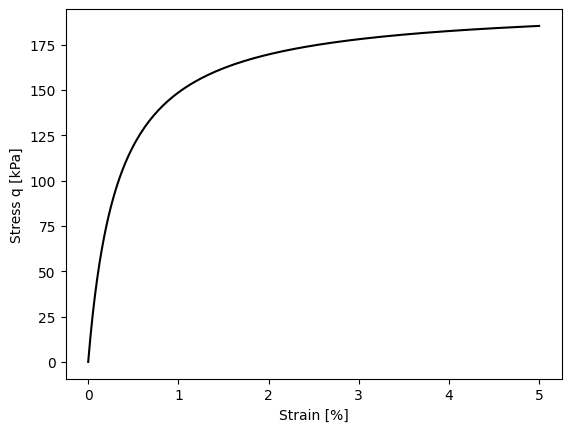

In [2]:
strain = np.linspace(0, 0.05, 200)
theta_demo = [60e3, 25, 10]          # Ei [kPa], phi [deg], c [kPa]

plt.plot(strain * 100, forward_model(theta_demo, strain), 'k')
plt.xlabel('Strain [%]'); plt.ylabel('Stress q [kPa]')
plt.show()

## 2. Measurement

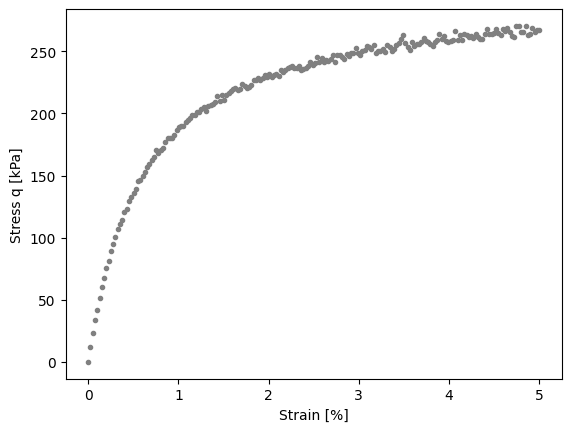

In [3]:
data = pd.read_csv('../data/synthetic_test.csv')
strain, q_meas = data['strain'].values, data['q_measured'].values

plt.plot(strain * 100, q_meas, '.', color='gray')
plt.xlabel('Strain [%]'); plt.ylabel('Stress q [kPa]')
plt.show()

## 3. Your guess

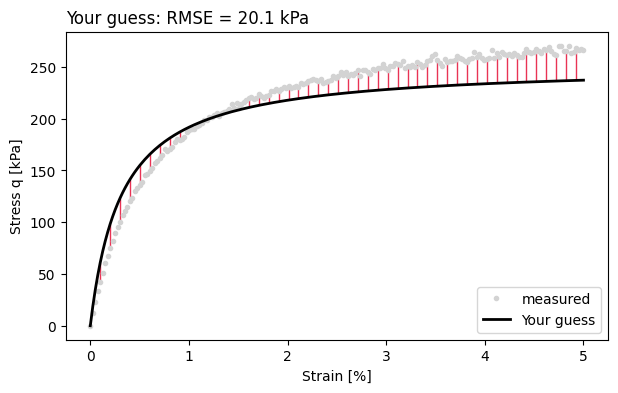

20.118636414192753

In [4]:
Ei  = 80e3    # kPa
phi = 28      # deg
c   = 15      # kPa

show_guess([Ei, phi, c], strain, q_meas)

## 3b. Guesses from the class

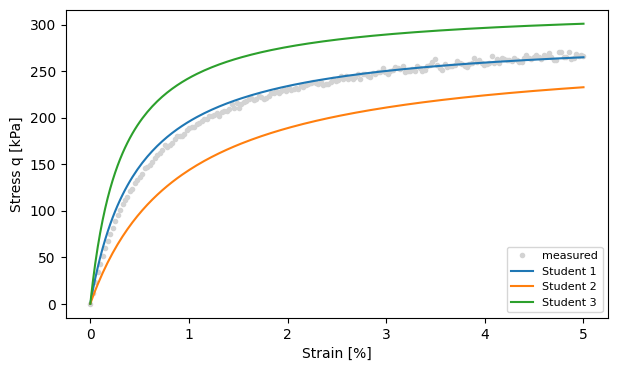

,Name,Ei [kPa],phi [deg],c [kPa],RMSE [kPa]
0,Student 1,60000.0,32,10,5.7
1,Student 2,30000.0,27,25,38.3
2,Student 3,100000.0,35,5,44.4


In [10]:
class_guesses = {
    'Student 1':  [60e3, 32, 10],
    'Student 2':   [30e3, 27, 25],
    'Student 3': [100e3, 35, 5],
}

rank_guesses(class_guesses, strain, q_meas)

## 3c. Sliders (optional)

In [6]:
from ipywidgets import interact, FloatSlider

@interact(Ei=FloatSlider(value=80e3, min=10e3, max=200e3, step=1e3),
          phi=FloatSlider(value=28, min=20, max=40, step=0.5),
          c=FloatSlider(value=15, min=0, max=30, step=0.5))
def try_it(Ei, phi, c):
    show_guess([Ei, phi, c], strain, q_meas)

interactive(children=(FloatSlider(value=80000.0, description='Ei', max=200000.0, min=10000.0, step=1000.0), Fl…

## 4. Let the computer search

In [11]:
bounds = [(10e3, 200e3), (20, 40), (0, 30)]
start  = [100e3, 25, 10]

result = calibrate(strain, q_meas, start, bounds)
theta_fit = result.x

## 5. Reveal: true values

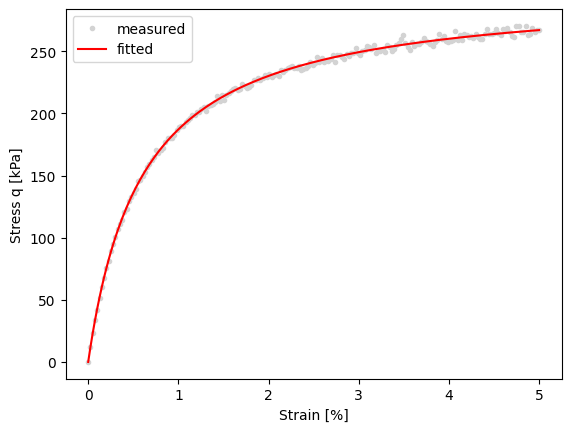

,true,fitted
Ei [kPa],50000.0,50039.5
phi [deg],30.0,30.6
c [kPa],20.0,17.5


In [8]:
true = json.load(open('../data/true_parameters.json'))
theta_true = [true['Ei'], true['phi'], true['c']]

plt.plot(strain * 100, q_meas, '.', color='lightgray', label='measured')
plt.plot(strain * 100, forward_model(theta_fit, strain), 'r', label='fitted')
plt.xlabel('Strain [%]'); plt.ylabel('Stress q [kPa]'); plt.legend()
plt.savefig('../graphics/fit.png', dpi=200)
plt.show()

table = pd.DataFrame({'true': theta_true, 'fitted': theta_fit},
                     index=['Ei [kPa]', 'phi [deg]', 'c [kPa]']).round(1)
table

## 6. Save

In [9]:
table.to_csv('../results/parameters.csv')